# Artificial-pinna direction decoder: data, training, evaluation

One microphone sits inside a 3D-printed asymmetric pinna. The pinna filters every sound differently depending on
where it comes from, so the spectrum at the microphone carries the direction. This notebook builds the decoder
that reads the direction back from that spectrum, end to end:

1. **Parameters**
2. **Data**: the measured pinna responses and the direction split
3. **Preprocessing**: simulated microphone signals and the input features
4. **Model**: a small MLP that classifies the direction
5. **Training**: with a fixed validation set, early stopping and best-checkpoint selection
6. **Evaluation**: the standardized test battery (separate test sets), compared with reference runs and with the
   previous team's CNN
7. **Summary**

The code lives in `pinna/` (one module per step); this notebook only calls it. Outputs (checkpoint, metrics,
figures) go to `runs/<RUN_NAME>/`. Setup: see `README.md`. With a GPU the whole notebook takes about
5 minutes (training about 1.5 min, the full test battery about 3 min; `QUICK = True` runs only the core test).

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from pinna import config, data, evaluate, features, model, plots, report, simulate, train

print("device:", config.DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1. Parameters
- `PROTOCOL`: which directions are used for training and which for testing (Section 2).
- `SEED`: one run is not evidence; compare designs over 3 or more seeds.
- `QUICK`: run only the core test instead of the full battery.
- `TrainConfig`: training settings; the defaults reproduce the reference runs. `train_pool=None` draws new examples
  every step; set e.g. `train_pool=6320` (the previous team's training-set size) to train on a fixed set and watch
  early stopping work against overfitting.

In [2]:
PROTOCOL = "seen"  # "seen" | "unseen_el" | "unseen_az"
SEED = 0
QUICK = False
RUN_NAME = f"{PROTOCOL}_s{SEED}"
cfg = train.TrainConfig(seed=SEED)  # e.g. train.TrainConfig(seed=SEED, steps=6000, train_pool=6320)

RUN_DIR = config.RUNS_DIR / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
reference = json.loads((config.CODE_DIR / "reference_results.json").read_text())
print(cfg)

TrainConfig(seed=0, steps=3000, batch=256, lr=0.002, weight_decay=0.0001, grad_clip=5.0, sources=('white', 'pink', 'band', 'harmonic', 'bursts', 'clicktrain'), snr_db=(10.0, 40.0), train_pool=None, eval_every=250, patience=4, val_seed=90004, val_draws=1, hidden=256, depth=2)


## 2. Data
The SOFA file holds the measured impulse response of the pinna (with the microphone) for 632 directions:
18 azimuths every 20 deg x 35 elevations every 5 deg, plus the two poles; 480 taps at 48 kHz.

**Direction split** (`data.split`):
- `seen`: train and test at all 632 directions, with different sounds.
- `unseen_el`: train at elevations that are multiples of 10 deg, test the elevations in between (5 deg away).
- `unseen_az`: every third azimuth column held out (20 deg from the nearest training column).

632 directions, 480 taps at 48000 Hz | seen: 632 training, 632 test directions


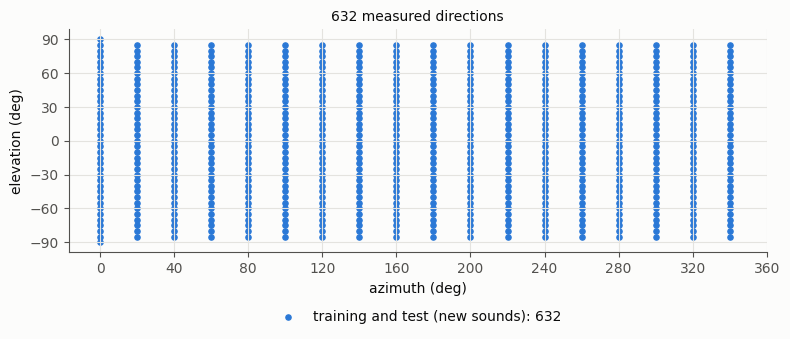

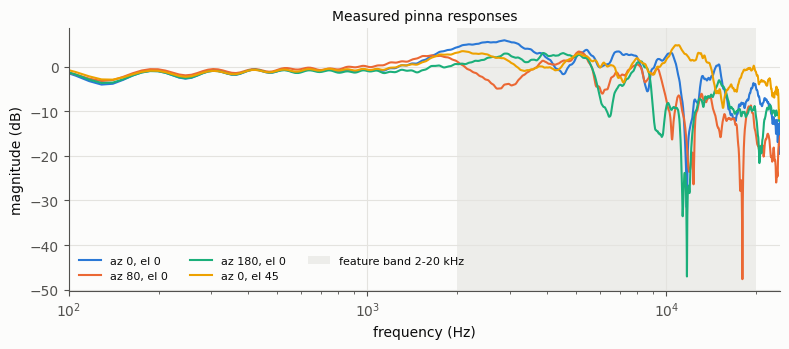

In [3]:
ir, az, el, sr = data.load_sofa()
train_idx, test_idx = data.split(PROTOCOL, az, el)
V = torch.as_tensor(data.unit_vec(az, el), dtype=torch.float32, device=config.DEVICE)  # unit vector per direction
V_cls = V[torch.as_tensor(train_idx, device=config.DEVICE)]  # the model's classes = the training directions
print(f"{len(ir)} directions, {ir.shape[1]} taps at {sr} Hz | {PROTOCOL}: {len(train_idx)} training, "
      f"{len(test_idx)} test directions")
plots.grid(az, el, train_idx, test_idx)
plt.show()
picks = [int(np.argmin(np.abs(az - a) + np.abs(el - e))) for a, e in ((0, 0), (90, 0), (180, 0), (0, 45))]
plots.responses(ir, az, el, sr, picks)
plt.show()

## 3. Preprocessing
**Forward model** (`simulate.make_batch`): a source signal is convolved with the response of its direction,
normalized to -20 dBFS, given a random gain of ±3 dB, and white sensor noise is added (SNR 10-40 dB in training).
Six source types: white, pink and band-limited noise (the previous team's three), harmonic (voice-like), noise
bursts and click trains. Each example is 1.37 s (65,536 samples).

**Features** (`features.features`): the frequency-differenced Welch spectrum. Power spectrum averaged over the
window, 2-20 kHz (192 bins of 94 Hz), log, minus its mean (removes loudness), differenced between neighbouring bins
(removes smooth source slopes): 191 numbers. Below, one direction with four different sources: the raw spectra
differ a lot, the features much less, because what is left is mostly the pinna.

direction az 80, el 0: waves (4, 65536) -> features (4, 191)


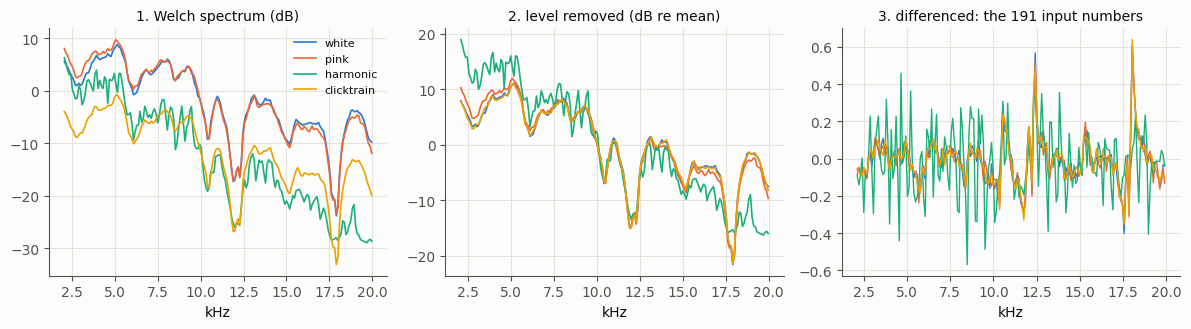

In [4]:
gen = torch.Generator().manual_seed(1)
d = picks[1]
kinds = ["white", "pink", "harmonic", "clicktrain"]
waves = simulate.make_batch(ir, np.full(len(kinds), d), kinds, gen, snr_db=30.0)
st = features.steps(waves)
print(f"direction az {round(az[d])}, el {round(el[d])}: waves {tuple(waves.shape)} -> features {tuple(st['features'].shape)}")
plots.feature_steps(st, features.FREQS, kinds)
plt.show()

## 4. Model
`model.DirectionMLP`: LayerNorm -> Linear(191, 256) -> GELU -> Linear(256, 256) -> GELU -> Linear(256, D), one
output per training direction. Trained with **soft labels** (a direction's neighbours on the sphere share the
target, sigma = 6 deg) and decoded as the probability-weighted mean of the classes within 15 deg of the most likely
one, so it can answer between grid points. The peak probability is a confidence score.

In [5]:
m0 = model.DirectionMLP(features.N_FEATURES, len(train_idx), cfg.hidden, cfg.depth)
print(m0)
print(f"parameters: {sum(p.numel() for p in m0.parameters()):,} | multiply-accumulates per window: "
      f"{model.count_macs(m0):,}")
del m0

DirectionMLP(
  (body): Sequential(
    (0): LayerNorm((191,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=191, out_features=256, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): GELU(approximate='none')
  )
  (head): Linear(in_features=256, out_features=632, bias=True)
)
parameters: 277,750 | multiply-accumulates per window: 276,224


## 5. Training
Three data sets are kept apart:
- **training**: new examples every step (or a fixed `train_pool`);
- **validation**: a fixed set drawn once (CPU seed 90004) at the training directions, one example per direction and
  source type, from the training distribution. It gives the curves below, decides early stopping and picks the
  checkpoint (lowest validation loss);
- **test**: Section 6, drawn with other seeds and never used for any choice.

A gap where the training loss keeps falling while the validation loss rises is overfitting; the kept checkpoint is
the one before it.

validation set: 3792 examples (4 s)


step   250  train loss 4.3258  val loss 2.8538  val error  8.15 deg (median 1.69)  *best  8 s


step   500  train loss 2.7568  val loss 2.6923  val error  6.42 deg (median 1.31)  *best  15 s


step   750  train loss 2.6550  val loss 2.6292  val error  5.86 deg (median 1.29)  *best  21 s


step  1000  train loss 2.6104  val loss 2.5847  val error  5.36 deg (median 1.10)  *best  28 s


...

step  2000  train loss 2.5171  val loss 2.5157  val error  4.23 deg (median 0.91)  *best  54 s


step  2250  train loss 2.5111  val loss 2.5028  val error  4.01 deg (median 0.85)  *best  60 s


step  2500  train loss 2.5023  val loss 2.4982  val error  3.88 deg (median 0.84)  *best  67 s


step  2750  train loss 2.4990  val loss 2.4963  val error  3.72 deg (median 0.82)  *best  74 s


step  3000  train loss 2.4877  val loss 2.4958  val error  3.61 deg (median 0.82)  *best  80 s
kept step 3000 (validation error 3.61 deg), 80 s; saved seen_s0/model.pt


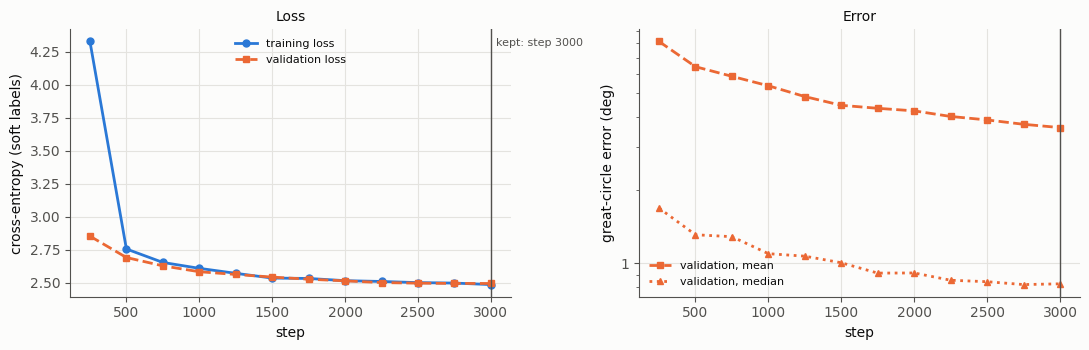

In [6]:
t0 = time.time()
val = train.make_validation_set(ir, train_idx, cfg)
print(f"validation set: {len(val['x'])} examples ({time.time() - t0:.0f} s)")
net, history, info = train.fit(ir, V, train_idx, cfg, val=val)
model.save(RUN_DIR / "model.pt", net, train_idx=train_idx, protocol=PROTOCOL, history=history, info=info)
print(f"kept step {info['best_step']} (validation error {info['best_val_err_mean']:.2f} deg), "
      f"{info['train_seconds']:.0f} s; saved {RUN_DIR.name}/model.pt")
fig = plots.training(history, info)
fig.savefig(RUN_DIR / "training_curves.png", dpi=130)
plt.show()

## 6. Evaluation
The test battery (`evaluate.conditions`): every condition has its own fixed seed, so the test waves are identical
on every machine and for every model. Test windows start 85 ms after the source switched on (a source switched on
at the first sample adds a click that gives the direction away). On `seen` the battery runs 73 conditions in
14 groups (frequency content, noise, level, window length, coloration, rooms, a changed pinna); on the held-out
splits it runs the core test on the held-out and on the training directions.

The references are the same battery run earlier on this design (3 seeds) and on the previous team's CNN retrained
with their own recipe (`reference_results.json`, numbers only).

In [7]:
predict = train.predictor(net, V_cls)
result = evaluate.run_battery(predict, PROTOCOL, ir, az, el, train_idx, test_idx, quick=QUICK)
report.save_run(RUN_DIR, result, history, info)

core                   n= 7584  mean   2.85 deg  median  0.77  < 5 deg  95.8 %     9 s


octave_500             n=  632  mean  81.50 deg  median 80.72  < 5 deg   0.9 %     9 s


octave_1000            n=  632  mean  24.28 deg  median  8.08  < 5 deg  35.9 %    10 s


octave_2000            n=  632  mean   2.23 deg  median  1.81  < 5 deg  93.0 %    11 s


octave_4000            n=  632  mean   1.17 deg  median  0.94  < 5 deg  99.8 %    11 s


...

irscale_0.99           n= 1896  mean   2.05 deg  median  1.75  < 5 deg  94.5 %   167 s


irscale_1.0            n= 1896  mean   0.81 deg  median  0.50  < 5 deg 100.0 %   169 s


irscale_1.01           n= 1896  mean   2.52 deg  median  1.95  < 5 deg  88.6 %   171 s


irscale_1.02           n= 1896  mean  17.68 deg  median  5.83  < 5 deg  43.5 %   173 s


irscale_1.04           n= 1896  mean  65.41 deg  median 62.97  < 5 deg   2.2 %   175 s


**Core test** (6 source types, 30 dB SNR; great-circle error in degrees)

| model | mean (deg) | median | P95 | % < 5 deg | % < 10 deg | % > 45 deg | Az-MAE | El-MAE |
|---|---|---|---|---|---|---|---|---|
| this run | 2.85 | 0.77 | 4.07 | 95.78 | 97.51 | 1.56 | 3.38 | 1.95 |
| MLP classifier (this design), reference runs (seeds 0, 1, 2) | 2.80 ± 0.05 | 0.75 ± 0.00 | 4.10 ± 0.16 | 95.93 ± 0.14 | 97.47 ± 0.04 | 1.48 ± 0.03 | 3.44 ± 0.05 | 1.91 ± 0.04 |
| Previous team's CNN, retrained with their recipe (seeds 42, 43, 44) | 25.08 ± 0.68 | 6.33 ± 0.28 | 117.6 ± 3.53 | 42.71 ± 1.63 | 60.46 ± 0.39 | 19.44 ± 0.39 | 28.65 ± 0.05 | 15.92 ± 0.44 |

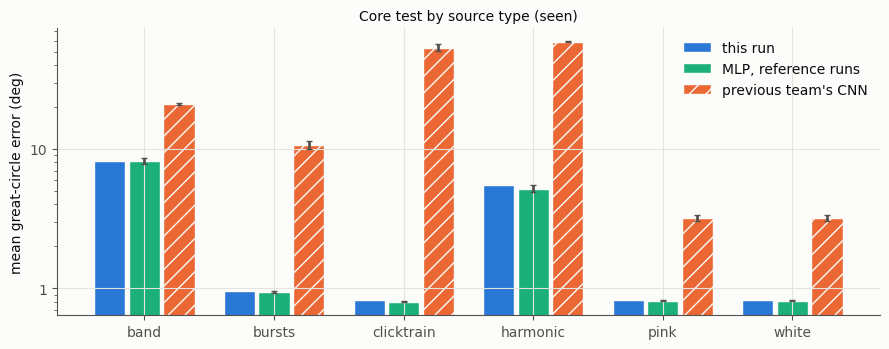

In [8]:
display(Markdown("**Core test** (6 source types, 30 dB SNR; great-circle error in degrees)\n\n"
                 + report.core_table(result, reference, PROTOCOL)))
fig = plots.core_by_source(result, reference, PROTOCOL)
fig.savefig(RUN_DIR / "core_by_source.png", dpi=130)
plt.show()

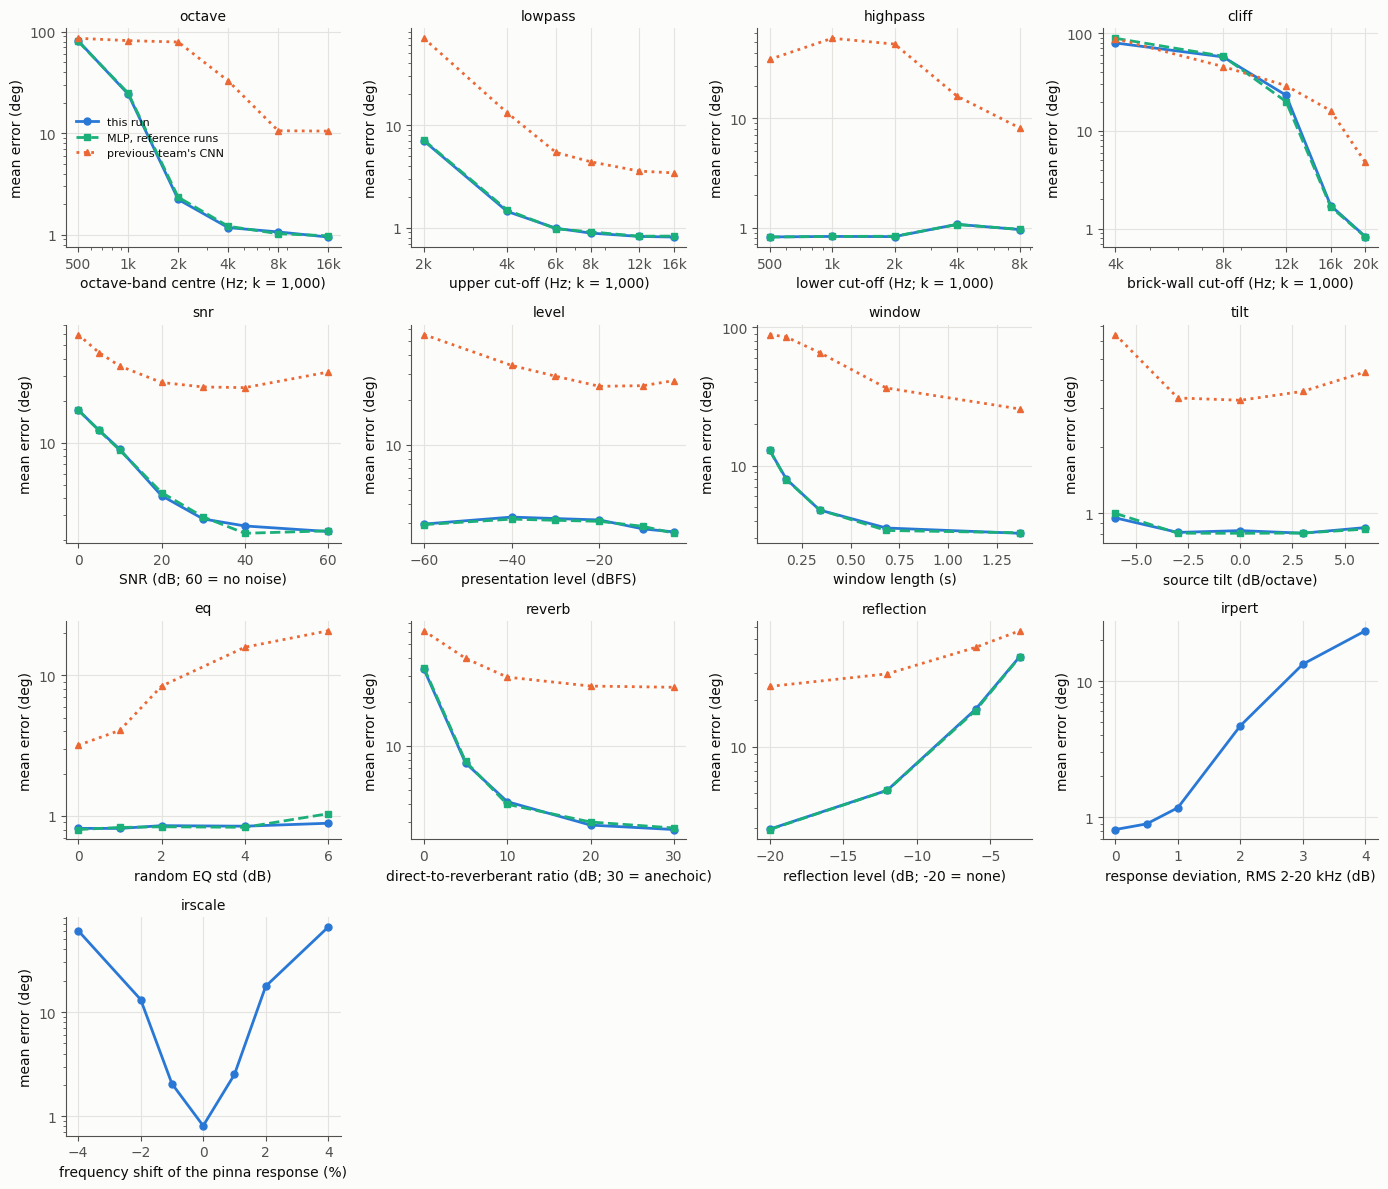

| condition | this run | MLP classifier (this design), reference runs | Previous team's CNN, retrained with their recipe |
|---|---|---|---|
| core | 2.85 | 2.80 | 25.08 |
| octave_500 | 81.50 | 80.30 | 86.23 |
| octave_1000 | 24.28 | 24.81 | 81.75 |
| octave_2000 | 2.23 | 2.34 | 79.17 |
| octave_4000 | 1.17 | 1.21 | 32.80 |
| octave_8000 | 1.06 | 1.02 | 10.58 |
| octave_16000 | 0.95 | 0.97 | 10.48 |
| lowpass_2000 | 7.01 | 7.12 | 70.13 |
| lowpass_4000 | 1.44 | 1.48 | 13.15 |
| lowpass_6000 | 0.99 | 0.97 | 5.41 |
| lowpass_8000 | 0.88 | 0.91 | 4.38 |
| lowpass_12000 | 0.82 | 0.82 | 3.55 |
| lowpass_16000 | 0.81 | 0.83 | 3.42 |
| highpass_500 | 0.82 | 0.82 | 34.66 |
| highpass_1000 | 0.83 | 0.83 | 54.17 |
| highpass_2000 | 0.83 | 0.83 | 47.91 |
| highpass_4000 | 1.07 | 1.07 | 15.96 |
| highpass_8000 | 0.96 | 0.96 | 8.18 |
| cliff_4000 | 79.81 | 89.09 | 88.20 |
| cliff_8000 | 57.41 | 58.40 | 45.73 |
| cliff_12000 | 23.25 | 20.02 | 29.15 |
| cliff_16000 | 1.72 | 1.67 | 16.15 |
| cliff_20000 | 0.83 | 0.82 | 4.76 |
| snr_clean | 2.30 | 2.33 | 32.16 |
| snr_40 | 2.52 | 2.23 | 24.85 |
| snr_30 | 2.83 | 2.93 | 25.13 |
| snr_20 | 4.16 | 4.39 | 27.07 |
| snr_10 | 8.96 | 8.83 | 35.52 |
| snr_5 | 12.30 | 12.24 | 44.40 |
| snr_0 | 17.19 | 17.16 | 59.82 |
| level_-60dBFS | 2.93 | 2.91 | 54.86 |
| level_-40dBFS | 3.27 | 3.17 | 34.02 |
| level_-30dBFS | 3.19 | 3.11 | 28.83 |
| level_-20dBFS | 3.12 | 3.06 | 24.64 |
| level_-10dBFS | 2.72 | 2.83 | 24.89 |
| level_-3dBFS | 2.60 | 2.54 | 26.93 |
| window_4096 | 12.93 | 12.88 | 88.50 |
| window_8192 | 7.99 | 7.92 | 85.01 |
| window_16384 | 4.76 | 4.78 | 65.50 |
| window_32768 | 3.54 | 3.39 | 36.34 |
| window_65536 | 3.24 | 3.27 | 25.64 |
| tilt_-6 | 0.95 | 1.00 | 6.44 |
| tilt_-3 | 0.82 | 0.81 | 3.32 |
| tilt_0 | 0.83 | 0.81 | 3.24 |
| tilt_3 | 0.81 | 0.81 | 3.56 |
| tilt_6 | 0.86 | 0.85 | 4.36 |
| eq_0 | 0.82 | 0.80 | 3.18 |
| eq_1 | 0.82 | 0.83 | 4.06 |
| eq_2 | 0.85 | 0.84 | 8.38 |
| eq_4 | 0.85 | 0.83 | 15.84 |
| eq_6 | 0.89 | 1.04 | 20.73 |
| reverb_drr_inf | 2.67 | 2.73 | 25.25 |
| reverb_drr_20 | 2.86 | 3.01 | 25.74 |
| reverb_drr_10 | 4.15 | 3.98 | 29.65 |
| reverb_drr_5 | 7.63 | 7.83 | 39.89 |
| reverb_drr_0 | 33.65 | 34.42 | 61.65 |
| reflection_none | 2.94 | 2.92 | 24.68 |
| reflection_-12 | 5.24 | 5.23 | 29.76 |
| reflection_-6 | 17.54 | 17.21 | 44.15 |
| reflection_-3 | 38.44 | 38.27 | 56.57 |
| irpert_0 | 0.81 | - | - |
| irpert_0.5 | 0.90 | - | - |
| irpert_1 | 1.18 | - | - |
| irpert_2 | 4.70 | - | - |
| irpert_3 | 13.31 | - | - |
| irpert_4 | 23.38 | - | - |
| irscale_0.96 | 60.45 | - | - |
| irscale_0.98 | 13.18 | - | - |
| irscale_0.99 | 2.05 | - | - |
| irscale_1.0 | 0.81 | - | - |
| irscale_1.01 | 2.52 | - | - |
| irscale_1.02 | 17.68 | - | - |
| irscale_1.04 | 65.41 | - | - |

In [9]:
fig = plots.groups(result, reference, PROTOCOL)
if fig is not None:
    fig.savefig(RUN_DIR / "condition_groups.png", dpi=130)
    plt.show()
    display(Markdown(report.groups_table(result, reference, PROTOCOL)))

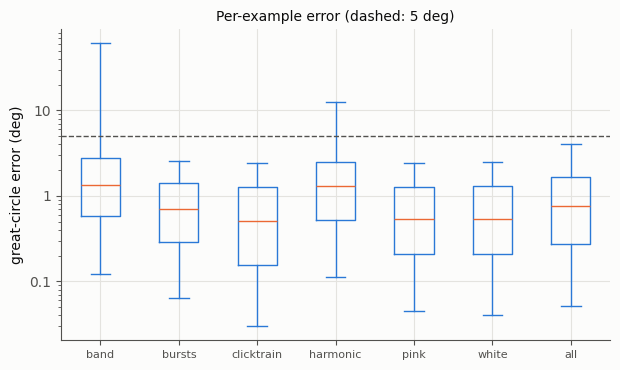

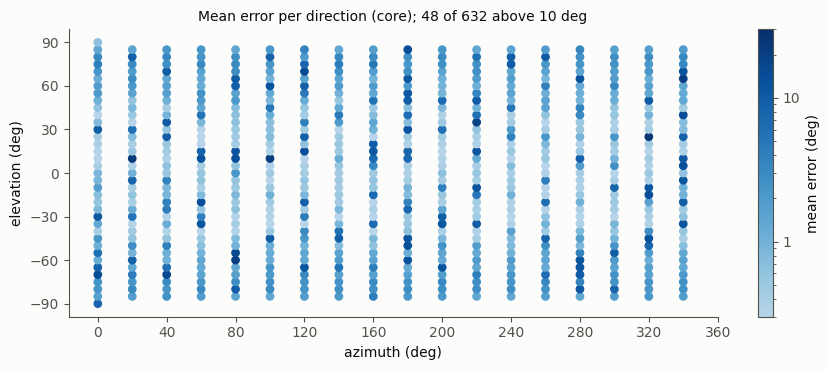

In [10]:
fig = plots.error_boxplots(result)
fig.savefig(RUN_DIR / "error_boxplots.png", dpi=130)
plt.show()
fig = plots.skymap(result, az, el)
fig.savefig(RUN_DIR / "error_skymap.png", dpi=130)
plt.show()

## 7. Summary

In [11]:
core = result["metrics"]["core"]
ref = reference["protocols"][PROTOCOL]["families"]
lines = [f"- **This run** ({RUN_NAME}): core mean error {core['gc_mean']:.2f} deg, median {core['gc_median']:.2f}, "
         f"{core['pct_lt5']:.1f} % within 5 deg; kept step {info['best_step']} of {cfg.steps} "
         f"(validation error {info['best_val_err_mean']:.2f} deg).",
         f"- **Reference runs of this design**: {ref['mlp']['core']['gc_mean'][0]:.2f} ± "
         f"{ref['mlp']['core']['gc_mean'][1]:.2f} deg; **previous team's CNN**: "
         f"{ref['prev_original']['core']['gc_mean'][0]:.1f} deg on the same test."]
if "conf_auroc_err_lt10" in core:
    lines.append(f"- **Confidence**: the peak probability separates errors under 10 deg from the rest with AUROC "
                 f"{core['conf_auroc_err_lt10']:.2f}; the 50 % most confident examples average "
                 f"{core['gc_mean_top50pct_conf']:.2f} deg.")
c = reference["cost"]
lines.append(f"- **Compute** (one window, one CPU thread): MLP {c['mlp']['total_ms']} ms, {c['mlp']['MMAC']} MMAC; "
             f"CNN {c['prev_original']['total_ms']} ms, {c['prev_original']['MMAC']:.0f} MMAC.")
lines.append(f"- Outputs in `runs/{RUN_NAME}/`: `model.pt`, `metrics.json`, `examples.npz`, figures.")
display(Markdown("\n".join(lines)))

- **This run** (seen_s0): core mean error 2.85 deg, median 0.77, 95.8 % within 5 deg; kept step 3000 of 3000 (validation error 3.61 deg).
- **Reference runs of this design**: 2.80 ± 0.05 deg; **previous team's CNN**: 25.1 deg on the same test.
- **Confidence**: the peak probability separates errors under 10 deg from the rest with AUROC 0.95; the 50 % most confident examples average 0.44 deg.
- **Compute** (one window, one CPU thread): MLP 0.9 ms, 0.276 MMAC; CNN 51.88 ms, 1559 MMAC.
- Outputs in `runs/seen_s0/`: `model.pt`, `metrics.json`, `examples.npz`, figures.

**Limits.** All sounds are synthetic and the pinna responses were measured in an anechoic chamber; the reverb and
reflection conditions are crude stand-ins for real rooms, and both models degrade sharply there. Held-out azimuth
columns fail for every model: the 20 deg azimuth grid is too coarse to learn the directions in between.